# TP Final — Inteligencia Artificial 2026 (UNAB)
## Etapa 3: Embeddings de caracteres y modelo de lenguaje simple
### Predicción del siguiente carácter sobre *"The Festival"* (H. P. Lovecraft)

**Estudiantes:** Leonardo Carabajal, Brian Fernandez, Thiago Montenegro Yerumini
**Docente:** Pablo Moreira

---

### Punto de partida
En la Etapa 2 el mejor modelo fue un MLP con Dropout que recibe los últimos 5 caracteres en one-hot. Ninguna técnica de regularización lo sacó de la zona del 48–49 % en Dev, y la brecha con Train quedó por encima de 20 pp. En esta etapa cambiamos la **representación de la entrada** y, después, el **tipo de modelo**:
1. **Red densa sobre embeddings (sección 2):** el mismo MLP de la Etapa 2, pero cada carácter entra como un vector denso aprendido en lugar de un one-hot. Comparamos embeddings de dos tamaños, **entrenados desde cero**.
2. **Modelo de lenguaje simple (sección 3):** una LSTM, que lee el contexto en orden y puede usar los 40 caracteres de la ventana, no solo los últimos 5.
3. **Embeddings de palabras pre-entrenados vs desde cero (sección 8):** la comparación que pide la consigna 4.3.B, con GloVe.

### Decisiones generales
1. **Embeddings de caracteres, no de palabras.** La tarea predice el siguiente carácter, así que cada token de entrada es un carácter.
2. **Los pre-entrenados se comparan con palabras.** GloVe y Word2Vec, los que menciona la consigna, tienen vectores de palabras, no de caracteres. Por eso la comparación entre pre-entrenados y desde cero se hace en la sección 8, prediciendo la siguiente palabra.
3. **Mismos datos y misma métrica:** la partición por bloques de la Etapa 1 y la accuracy en Dev. Test sigue sin usarse hasta la Etapa 5.
4. **Misma configuración de entrenamiento que el ganador de la Etapa 2** (learning rate, Dropout, batch y épocas), para que la diferencia se deba a la representación o al modelo. R3 y R4 suman Early Stopping y `clipnorm` (sección 3.2).
5. **5 semillas por modelo**, con media ± desvío.

---
# 1. Configuración y datos

In [1]:
# ==============================================================================
# 1.1 CONFIGURACIÓN DEL ENTORNO
# ==============================================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import json
import time
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

SEED = 42
SEEDS = [42, 123, 456, 789, 2026]
np.random.seed(SEED)

print(f"TensorFlow {tf.__version__} | Keras {keras.__version__}")

TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
# ==============================================================================
# 1.2 CARGA DEL TEXTO LIMPIO Y DE LA PARTICIÓN DE LA ETAPA 1
# ==============================================================================
BASE_DIR = Path.cwd().parent if (Path.cwd().parent / "data").exists() else Path.cwd()
PROC = BASE_DIR / "data" / "processed"

text = (PROC / "The_Festival_clean.txt").read_text(encoding="utf-8")
splits = json.load(open(PROC / "splits_bloques.json", encoding="utf-8"))

L = splits["L"]
limites = splits["limites_bloques"]
bloques_split = splits["bloques"]
vocabulary = list(splits["vocabulario"])
char2idx = {c: i for i, c in enumerate(vocabulary)}
idx2char = {i: c for c, i in char2idx.items()}
# Muestra el espacio y el salto de línea de forma legible en tablas y gráficos
vis = lambda c: {" ": "<SP>", "\n": "<NL>"}.get(c, c)
V = len(vocabulary)

def ventanas_de_bloques(ids):
    X, y = [], []
    for b in ids:
        ini, fin = limites[b]
        for i in range(ini, fin - L):
            X.append(text[i:i+L])
            y.append(text[i+L])
    return X, y

X_train, y_train = ventanas_de_bloques(bloques_split["train"])
X_dev,   y_dev   = ventanas_de_bloques(bloques_split["dev"])

# Entrada como índices enteros: (N, L)
a_indices = lambda X: np.array([[char2idx[c] for c in x] for x in X], dtype=np.int32)
Xi_train, Xi_dev = a_indices(X_train), a_indices(X_dev)
yi_train = np.array([char2idx[c] for c in y_train], dtype=np.int32)
yi_dev   = np.array([char2idx[c] for c in y_dev], dtype=np.int32)

print(f"|V| = {V} | L = {L}")
print(f"Train: {len(X_train):,} muestras | Dev: {len(X_dev):,} muestras")

|V| = 64 | L = 40
Train: 12,780 muestras | Dev: 2,880 muestras


In [3]:
# ==============================================================================
# 1.3 REFERENCIAS DE LAS ETAPAS 1 Y 2
# ==============================================================================
ref_base = json.load(open(PROC / "baseline_dev.json", encoding="utf-8"))
reg2 = json.load(open(PROC / "resultados_modelos.json", encoding="utf-8"))
ref2 = reg2["configuraciones"][reg2["ganador"]]

# Configuración de entrenamiento heredada del ganador de la Etapa 2
CFG2 = ref2["config"]
LR = CFG2["lr"]
DROPOUT = CFG2.get("dropout", 0.0)
EPOCAS = reg2["learning_rate"]["epocas"]
BATCH = 128
K = ref_base["K"]

print(f"Baseline (Etapa 1): {ref_base['accuracy_dev']*100:.2f}% en Dev")
print(f"Ganador Etapa 2 ({reg2['ganador']}): {ref2['dev_acc_mean']*100:.2f}% ± {ref2['dev_acc_std']*100:.2f}% en Dev")
print(f"Configuración heredada: lr = {LR:g} | Dropout = {DROPOUT} | {EPOCAS} épocas | batch {BATCH} | K = {K}")

Baseline (Etapa 1): 40.83% en Dev
Ganador Etapa 2 (Dropout 0.05): 48.71% ± 0.52% en Dev
Configuración heredada: lr = 0.0005 | Dropout = 0.05 | 100 épocas | batch 128 | K = 5


---
# 2. Consigna 4.3.B: Red densa sobre embeddings
Mantenemos la red de la Etapa 2 (Dense 128 → 64 → 32 con ReLU, Dropout y salida softmax) y los mismos últimos $K = 5$ caracteres. Solo cambia cómo entra cada carácter:

| Modelo | Representación de cada carácter |
|---|---|
| **E0 — One-hot (Etapa 2)** | vector one-hot de 64 posiciones; repetimos el ganador de la Etapa 2 en las mismas condiciones |
| **E1 — Desde cero, 16 dim.** | embedding de 16 dimensiones aprendido junto con la red |
| **E2 — Desde cero, 300 dim.** | embedding de 300 dimensiones aprendido junto con la red |

E0 contra E1 y E2 muestra qué cambia al pasar del one-hot a un embedding aprendido; E1 contra E2, el efecto de la dimensión.

In [4]:
# ==============================================================================
# 2.1 CONSTRUCCIÓN, ENTRENAMIENTO Y EVALUACIÓN CON 5 SEMILLAS
# ==============================================================================
def construir_modelo(tipo, k=K, emb_dim=16, emb_init=None, emb_trainable=True, dropout=DROPOUT, unidades_lstm=128):
    """
    tipo = "onehot": MLP de la Etapa 2 sobre one-hot aplanado.
    tipo = "densa":  Embedding -> Flatten -> MLP 128-64-32.
    tipo = "lstm":   Embedding -> LSTM -> Dropout -> softmax.
    """
    entrada = layers.Input(shape=(k,), dtype="int32")
    if tipo == "onehot":
        # One-hot exacto: embedding fijo con la matriz identidad
        x = layers.Embedding(V, V, embeddings_initializer=keras.initializers.Identity(), trainable=False)(entrada)
    else:
        init = keras.initializers.Constant(emb_init) if emb_init is not None else "uniform"
        x = layers.Embedding(V, emb_dim, embeddings_initializer=init, trainable=emb_trainable, name="embedding")(entrada)

    if tipo in ("onehot", "densa"):
        x = layers.Flatten()(x)
        for u in [128, 64, 32]:
            x = layers.Dense(u, activation="relu")(x)
            if dropout > 0:
                x = layers.Dropout(dropout)(x)
    else:
        x = layers.LSTM(unidades_lstm)(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)

    salida = layers.Dense(V, activation="softmax")(x)
    return keras.Model(entrada, salida)

def evaluar(constructor, k, epochs=EPOCAS, seeds=SEEDS, lr=None, clipnorm=None, use_es=False, patience=5):
    """Entrena con cada semilla y devuelve (resumen, historial y modelo de la semilla 42)."""
    Xtr, Xdv = Xi_train[:, -k:], Xi_dev[:, -k:]
    corridas = []
    for s in seeds:
        keras.utils.set_random_seed(s)
        modelo = constructor()
        modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr or LR, clipnorm=clipnorm),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cbs = []
        if use_es:
            cbs.append(callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))
        t0 = time.perf_counter()
        h = modelo.fit(Xtr, yi_train, validation_data=(Xdv, yi_dev), epochs=epochs, batch_size=BATCH,
                       callbacks=cbs, verbose=0)
        t_run = time.perf_counter() - t0
        if s == SEED:
            h42, m42 = h.history, modelo
        loss_tr, acc_tr = [float(v) for v in modelo.evaluate(Xtr, yi_train, verbose=0)]
        loss_dv, acc_dv = [float(v) for v in modelo.evaluate(Xdv, yi_dev, verbose=0)]
        va = h.history["val_accuracy"]
        corridas.append({"seed": s, "tiempo": t_run, "train_acc": acc_tr, "dev_acc": acc_dv,
                         "brecha": acc_tr - acc_dv, "dev_loss": loss_dv, "dev_perp": float(np.exp(loss_dv)),
                         "pico_acc": float(max(va)), "ep_pico_acc": int(np.argmax(va)) + 1,
                         "epocas": len(h.history["loss"])})
    df_c = pd.DataFrame(corridas)
    resumen = {"params": int(sum(np.prod(w.shape) for w in m42.trainable_weights)), "k": k, "dev_acc_min": float(df_c["dev_acc"].min()), "corridas": corridas}
    for col in df_c.columns.drop("seed"):
        resumen[f"{col}_mean"] = float(df_c[col].mean())
        resumen[f"{col}_std"] = float(df_c[col].std())
    return resumen, h42, m42

MODELOS_DENSOS = {
    "E0 — One-hot (Etapa 2)":       lambda: construir_modelo("onehot"),
    "E1 — Desde cero, 16 dim.":     lambda: construir_modelo("densa", emb_dim=16),
    "E2 — Desde cero, 300 dim.":    lambda: construir_modelo("densa", emb_dim=300),
}

resultados, historiales, modelos = {}, {}, {}
for nombre, constructor in MODELOS_DENSOS.items():
    resultados[nombre], historiales[nombre], modelos[nombre] = evaluar(constructor, k=K)
    r = resultados[nombre]
    print(f"  {nombre:<30} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | brecha {r['brecha_mean']*100:.2f} pp | {r['tiempo_mean']:.0f} s por corrida")

def tabla(nombres):
    filas = []
    for n in nombres:
        r = resultados[n]
        filas.append({"Modelo": n, "Parámetros entrenables": f"{r['params']:,}",
                      "Dev Acc (μ ± σ)": f"{r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}%",
                      "Peor semilla": f"{r['dev_acc_min']*100:.2f}%",
                      "Δ vs Etapa 2": f"{(r['dev_acc_mean'] - ref2['dev_acc_mean'])*100:+.2f} pp",
                      "Train Acc": f"{r['train_acc_mean']*100:.2f}%",
                      "Brecha": f"{r['brecha_mean']*100:.2f} pp",
                      "Dev Loss": f"{r['dev_loss_mean']:.4f}",
                      "Perplejidad": f"{r['dev_perp_mean']:.2f}",
                      "Pico Dev (época)": f"{r['pico_acc_mean']*100:.2f}% ({r['ep_pico_acc_mean']:.0f})",
                      "Épocas": f"{r['epocas_mean']:.0f}"})
    return pd.DataFrame(filas).set_index("Modelo")

display(tabla(MODELOS_DENSOS))

  E0 — One-hot (Etapa 2)         Dev: 48.71% ± 0.52% | brecha 20.72 pp | 35 s por corrida


  E1 — Desde cero, 16 dim.       Dev: 47.88% ± 0.73% | brecha 10.11 pp | 25 s por corrida


  E2 — Desde cero, 300 dim.      Dev: 49.51% ± 0.81% | brecha 25.62 pp | 40 s por corrida


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
E0 — One-hot (Etapa 2),"53,536",48.71% ± 0.52%,48.16%,+0.00 pp,69.43%,20.72 pp,2.0363,7.66,49.26% (88),100
"E1 — Desde cero, 16 dim.","23,840",47.88% ± 0.73%,47.05%,-0.83 pp,57.99%,10.11 pp,1.8739,6.51,48.21% (95),100
"E2 — Desde cero, 300 dim.","223,776",49.51% ± 0.81%,48.58%,+0.81 pp,75.13%,25.62 pp,2.1590,8.66,50.05% (76),100


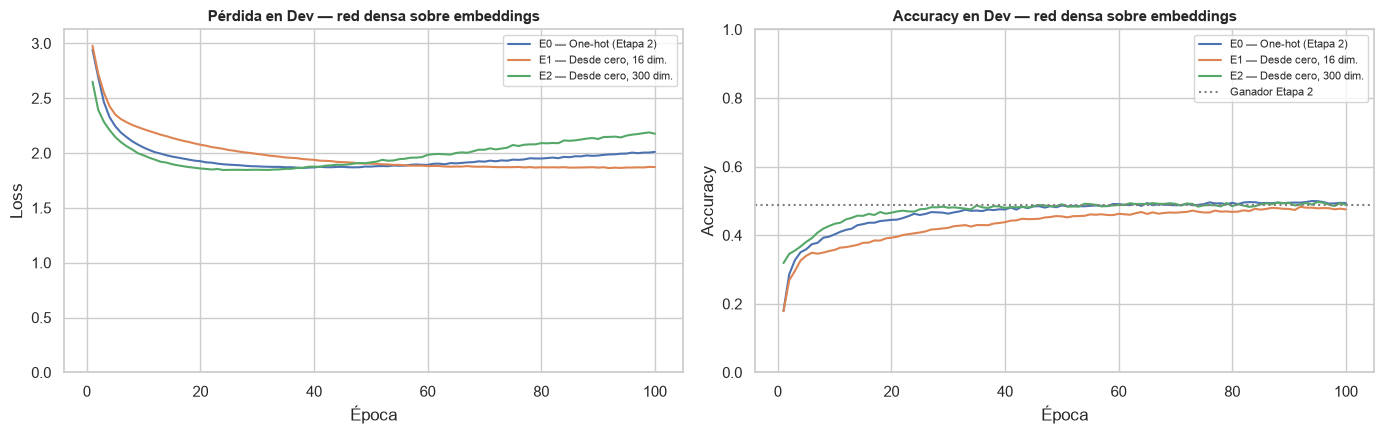

In [5]:
# ==============================================================================
# 2.2 CURVAS DE VALIDACIÓN (semilla 42)
# ==============================================================================
def graficar_curvas(nombres, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for n in nombres:
        h = historiales[n]
        ep = range(1, len(h["loss"]) + 1)
        axes[0].plot(ep, h["val_loss"], label=n)
        axes[1].plot(ep, h["val_accuracy"], label=n)
    axes[1].axhline(ref2["dev_acc_mean"], color="gray", linestyle=":", label="Ganador Etapa 2")
    axes[0].set_ylim(0, max(max(historiales[n]["val_loss"]) for n in nombres) * 1.05)
    axes[1].set_ylim(0, 1)
    axes[0].set_title(f"Pérdida en Dev — {titulo}", fontsize=11, fontweight="bold")
    axes[1].set_title(f"Accuracy en Dev — {titulo}", fontsize=11, fontweight="bold")
    axes[0].set_ylabel("Loss")
    axes[1].set_ylabel("Accuracy")
    for ax in axes:
        ax.set_xlabel("Época")
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

graficar_curvas(MODELOS_DENSOS, "red densa sobre embeddings")

**Interpretación.**
- **E0 reproduce exactamente el ganador de la Etapa 2** ($48,71\% \pm 0,52\%$), así que las comparaciones de esta etapa se hacen en las mismas condiciones.
- **Desde cero, la dimensión cambia el balance entre acierto y sobreajuste.** Con 16 dimensiones (E1) la accuracy baja a $47,88\%$, pero la brecha cae a $10,11$ pp y la perplejidad a $6,51$, la mejor de la sección: una representación chica funciona como regularización. Con 300 dimensiones (E2) la accuracy sube a $49,51\%$ ($+0,81$ pp sobre E0), pero la brecha crece a $25,62$ pp y la perplejidad empeora a $8,66$. La mejora de E2 sobre E0 es del tamaño del desvío entre semillas, así que es chica.

En resumen: pasar del one-hot a un embedding aprendido mejora poco la accuracy. El tamaño del embedding mueve sobre todo el balance entre acierto y sobreajuste.

---
# 3. Modelo de lenguaje simple: LSTM
La red densa mira los 5 caracteres como un bloque fijo. Una LSTM los lee en orden y mantiene un estado que resume lo que vino antes, así que puede aprovechar contextos más largos sin que crezca la cantidad de parámetros. Usamos la mejor representación de la sección 2 y probamos dos largos de contexto:

| Modelo | Contexto | Para qué |
|---|---|---|
| **R1 — LSTM, 5 caracteres** | los mismos $K = 5$ | separa el efecto de leer en orden del efecto de ver más contexto |
| **R2 — LSTM, 40 caracteres** | la ventana completa ($L = 40$) | mide cuánto aporta el contexto largo |

La LSTM tiene 128 unidades, seguida de Dropout y la capa de salida softmax.

Representación elegida para la LSTM: E2 — Desde cero, 300 dim.



  R1 — LSTM, 5 caracteres    Dev: 49.69% ± 0.12% | brecha 28.67 pp | 100 s por corrida


  R2 — LSTM, 40 caracteres   Dev: 45.06% ± 1.70% | brecha 27.41 pp | 583 s por corrida


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
E0 — One-hot (Etapa 2),"53,536",48.71% ± 0.52%,48.16%,+0.00 pp,69.43%,20.72 pp,2.0363,7.66,49.26% (88),100
"E2 — Desde cero, 300 dim.","223,776",49.51% ± 0.81%,48.58%,+0.81 pp,75.13%,25.62 pp,2.1590,8.66,50.05% (76),100
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
"R2 — LSTM, 40 caracteres","247,104",45.06% ± 1.70%,43.06%,-3.65 pp,72.48%,27.41 pp,2.1420,8.54,48.32% (51),100


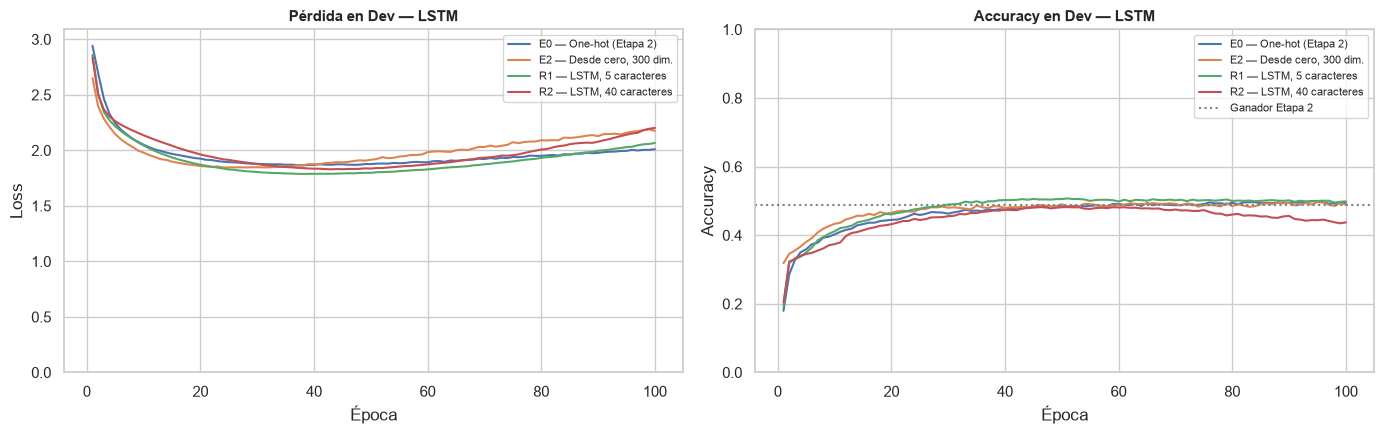

In [6]:
# ==============================================================================
# 3.1 LSTM CON LA MEJOR REPRESENTACIÓN DE LA SECCIÓN 2
# ==============================================================================
candidatos_emb = [n for n in MODELOS_DENSOS if not n.startswith("E0")]
MEJOR_EMB = max(candidatos_emb, key=lambda n: resultados[n]["dev_acc_mean"])
cfg_emb = {
    "E1 — Desde cero, 16 dim.":     dict(emb_dim=16),
    "E2 — Desde cero, 300 dim.":    dict(emb_dim=300),
}[MEJOR_EMB]
print(f"Representación elegida para la LSTM: {MEJOR_EMB}\n")

MODELOS_LSTM = {
    "R1 — LSTM, 5 caracteres":  (lambda: construir_modelo("lstm", k=K, **cfg_emb), K),
    "R2 — LSTM, 40 caracteres": (lambda: construir_modelo("lstm", k=L, **cfg_emb), L),
}
# R2 tarda unos 54 minutos (5 semillas). La primera corrida guarda sus resultados y curvas en un caché;
# las siguientes los cargan, salvo que cambie la configuración. Las semillas fijas dan los mismos números.
R2 = "R2 — LSTM, 40 caracteres"
CACHE_R2 = PROC / "cache_R2.json"
cfg_r2 = {"emb": cfg_emb, "lr": LR, "dropout": DROPOUT, "epocas": EPOCAS, "batch": BATCH, "seeds": SEEDS}
cache = json.load(open(CACHE_R2, encoding="utf-8")) if CACHE_R2.exists() else None

for nombre, (constructor, k) in MODELOS_LSTM.items():
    if nombre == R2 and cache is not None and cache["config"] == cfg_r2:
        resultados[nombre], historiales[nombre] = cache["resultado"], cache["historial"]
        print(f"  {nombre}: cargado de {CACHE_R2.name}")
    else:
        resultados[nombre], historiales[nombre], modelos[nombre] = evaluar(constructor, k=k)
        if nombre == R2:
            historial = {m: [float(v) for v in vals] for m, vals in historiales[nombre].items()}
            json.dump({"config": cfg_r2, "resultado": resultados[nombre], "historial": historial},
                      open(CACHE_R2, "w", encoding="utf-8"), ensure_ascii=False)
    r = resultados[nombre]
    print(f"  {nombre:<26} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | brecha {r['brecha_mean']*100:.2f} pp | {r['tiempo_mean']:.0f} s por corrida")

display(tabla(["E0 — One-hot (Etapa 2)", MEJOR_EMB] + list(MODELOS_LSTM)))
graficar_curvas(["E0 — One-hot (Etapa 2)", MEJOR_EMB] + list(MODELOS_LSTM), "LSTM")

**Interpretación.**
- **La LSTM con 5 caracteres (R1) es la mejor de esta sección:** $49,69\% \pm 0,12\%$, la más estable entre semillas. Frente a la red densa con la misma representación (E2) gana solo $0,18$ pp: con 5 caracteres, leerlos en orden aporta poco sobre verlos como bloque. Sobreajusta (brecha de $28,67$ pp): su accuracy toca un pico de $50,81\%$ en la época 61 y después baja un poco hasta la 100.
- **La LSTM con 40 caracteres (R2) rinde peor:** $45,06\% \pm 1,70\%$, con el mayor desvío entre semillas. Llega a su pico ($48,32\%$) en la época 51 y de ahí en adelante cae sin parar: sin Early Stopping, el contexto largo termina en sobreajuste. Además tarda $583$ s por corrida, casi 6 veces más que R1.

La configuración heredada se ajustó para el MLP, no para una LSTM. En la sección 3.2 corregimos cuándo parar.

### 3.2 La LSTM de 40 caracteres con Early Stopping
R2 llega a su mejor accuracy alrededor de la época 51 y después empeora: sobreajusta. Corregimos cuándo parar: Adam con `clipnorm=1.0` y Early Stopping (paciencia 5, mira `val_loss` y recupera los pesos de la mejor época). El learning rate es el elegido en la Etapa 2 ($0,0005$), el mismo para R3 y R4 (sección 3.3); también probamos $0,005$ (ver `docs/EXPERIMENTOS_RETIRADOS.md`). `clipnorm` es *gradient clipping*: si la norma del gradiente supera 1, se recorta, lo que protege a la red recurrente de los gradientes explosivos. Este modelo es **R3**.

  R3 — LSTM 40 + ES          Dev: 47.76% ± 0.55% | brecha 9.20 pp | 53 épocas | 284 s por corrida


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
"R2 — LSTM, 40 caracteres","247,104",45.06% ± 1.70%,43.06%,-3.65 pp,72.48%,27.41 pp,2.1420,8.54,48.32% (51),100
R3 — LSTM 40 + ES,"247,104",47.76% ± 0.55%,47.22%,-0.94 pp,56.96%,9.20 pp,1.8174,6.16,48.01% (50),53


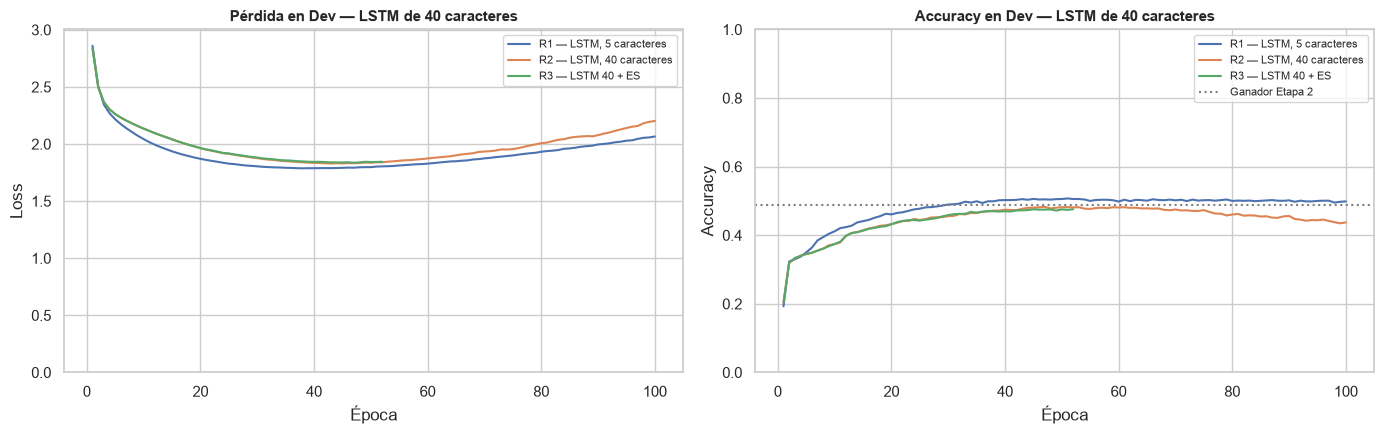

In [7]:
# ==============================================================================
# 3.2 LSTM DE 40 CARACTERES CON EARLY STOPPING (clipnorm y Early Stopping, 5 semillas)
# ==============================================================================
LR_LSTM = LR  # el learning rate elegido en la Etapa 2
CLIPNORM = 1.0
R3 = "R3 — LSTM 40 + ES"

if R3 not in resultados:
    resultados[R3], historiales[R3], modelos[R3] = evaluar(
        lambda: construir_modelo("lstm", k=L, **cfg_emb), k=L, lr=LR_LSTM, clipnorm=CLIPNORM, use_es=True, patience=5)
    resultados[R3]["config_lstm"] = {"emb": cfg_emb, "dropout": DROPOUT, "lr": LR_LSTM, "clipnorm": CLIPNORM, "es_patience": 5}
r = resultados[R3]
print(f"  {R3:<26} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | "
      f"brecha {r['brecha_mean']*100:.2f} pp | {r['epocas_mean']:.0f} épocas | {r['tiempo_mean']:.0f} s por corrida")

display(tabla(["R1 — LSTM, 5 caracteres", "R2 — LSTM, 40 caracteres", R3]))
graficar_curvas(["R1 — LSTM, 5 caracteres", "R2 — LSTM, 40 caracteres", R3], "LSTM de 40 caracteres")

**Interpretación.**
- **Cortar a tiempo recupera parte de lo que perdía R2.** R3 sube de $45,06\%$ a $47,76\% \pm 0,55\%$ ($+2,70$ pp), con un desvío entre semillas tres veces menor ($0,55$ contra $1,70$ pp), y la brecha cae de $27,41$ a $9,20$ pp. Entrena 53 épocas en promedio y tarda $284$ s por corrida, contra $583$ s de R2.
- **Pero no alcanza a la LSTM de 5 caracteres:** queda $1,93$ pp por debajo de R1. Como R1 y R3 no se entrenaron igual, todavía no sabemos si la diferencia viene del contexto o del esquema; eso lo separa la sección 3.3.

### 3.3 Control: la LSTM de 5 caracteres con el mismo esquema
R1 y R3 no se entrenaron igual: R1 usó la configuración heredada (learning rate fijo y 100 épocas) y R3, `clipnorm` y Early Stopping. Comparadas así, no se puede saber si la diferencia viene del largo del contexto o del esquema de entrenamiento. Para aislar el contexto, entrenamos la LSTM de 5 caracteres con el mismo esquema que R3 (Dropout $0,05$, embedding de 300 dimensiones, learning rate de $0,0005$, `clipnorm=1.0` y Early Stopping con paciencia 5). Este modelo es **R4**.

  R4 — LSTM 5 + ES               Dev: 50.07% ± 0.54% | brecha 10.43 pp | 47 épocas | 45 s por corrida
  Ganancia sobre R1: +0.38 pp (desvío de R1: 0.12 pp)
  Diferencia con R3 (40 caracteres, mismo esquema): +2.31 pp


,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
R4 — LSTM 5 + ES,"247,104",50.07% ± 0.54%,49.34%,+1.36 pp,60.50%,10.43 pp,1.7774,5.91,50.49% (43),47
R3 — LSTM 40 + ES,"247,104",47.76% ± 0.55%,47.22%,-0.94 pp,56.96%,9.20 pp,1.8174,6.16,48.01% (50),53


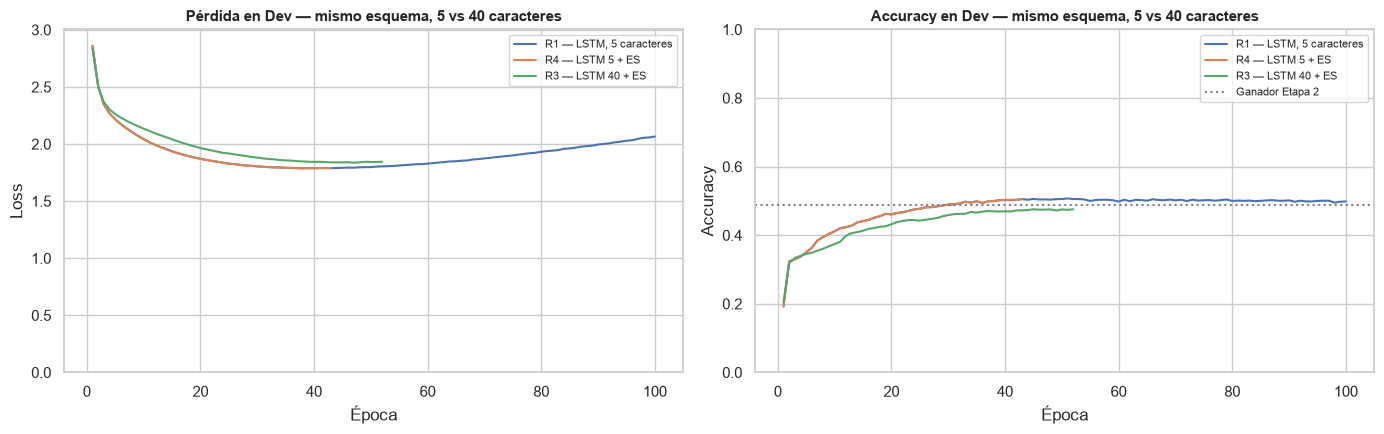

In [8]:
# ==============================================================================
# 3.3 CONTROL: LSTM DE 5 CARACTERES CON EL ESQUEMA DE R3 (5 semillas)
# ==============================================================================
R4 = "R4 — LSTM 5 + ES"
if R4 not in resultados:
    resultados[R4], historiales[R4], modelos[R4] = evaluar(
        lambda: construir_modelo("lstm", k=K, **cfg_emb), k=K, lr=LR_LSTM, clipnorm=CLIPNORM, use_es=True, patience=5)
    resultados[R4]["config_lstm"] = {"emb": {k: v for k, v in cfg_emb.items() if k != "emb_init"},
                                     "dropout": DROPOUT, "lr": LR_LSTM, "clipnorm": CLIPNORM, "es_patience": 5}
r = resultados[R4]
print(f"  {R4:<30} Dev: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | "
      f"brecha {r['brecha_mean']*100:.2f} pp | {r['epocas_mean']:.0f} épocas | {r['tiempo_mean']:.0f} s por corrida")
print(f"  Ganancia sobre R1: {(r['dev_acc_mean'] - resultados['R1 — LSTM, 5 caracteres']['dev_acc_mean'])*100:+.2f} pp "
      f"(desvío de R1: {resultados['R1 — LSTM, 5 caracteres']['dev_acc_std']*100:.2f} pp)")
print(f"  Diferencia con R3 (40 caracteres, mismo esquema): {(r['dev_acc_mean'] - resultados[R3]['dev_acc_mean'])*100:+.2f} pp")

comparadas_33 = ["R1 — LSTM, 5 caracteres", R4, R3]
display(tabla(comparadas_33))
graficar_curvas(comparadas_33, "mismo esquema, 5 vs 40 caracteres")

**Interpretación.**
- **R4 es R1 cortado a tiempo.** Es el mismo modelo con el mismo learning rate, y en las curvas de la semilla 42 los dos van casi superpuestos hasta que Early Stopping corta a R4 (47 épocas en promedio) y recupera los pesos de menor pérdida en Dev.
- **En accuracy, R4 y R1 empatan:** $50,07\% \pm 0,54\%$ contra $49,69\% \pm 0,12\%$. La diferencia ($+0,38$ pp) es menor que el desvío de R4.
- **En todo lo demás, R4 es mejor:** la brecha baja de $28,67$ a $10,43$ pp, la perplejidad de $7,64$ a $5,91$ (la mejor de la etapa) y el tiempo de $100$ a $45$ s por corrida. R1 llega a la época 100 con las probabilidades peor repartidas, aunque siga acertando el primer puesto casi igual.
- **Con el mismo esquema, el contexto corto gana:** R4 supera a R3 por $2,31$ pp. Con un learning rate de $0,005$ pasa lo mismo ($49,20\%$ contra $48,40\%$). Con unas 12.800 ventanas de Train, los 35 caracteres extra no se aprovechan.

---
# 4. Comparación con la Etapa 2
El **modelo ganador de la Etapa 3** es el de mayor accuracy media en Dev entre todos los de las secciones 2 y 3. Reportamos su mejora sobre el ganador de la Etapa 2 y sobre el baseline.

In [9]:
# ==============================================================================
# 4.1 TABLA FINAL Y MEJORA SOBRE LA ETAPA 2
# ==============================================================================
GANADOR3 = max(resultados, key=lambda n: resultados[n]["dev_acc_mean"])
r3 = resultados[GANADOR3]

print(f"Ganador de la Etapa 3: {GANADOR3}")
print(f"  • Dev: {r3['dev_acc_mean']*100:.2f}% ± {r3['dev_acc_std']*100:.2f}% (peor semilla {r3['dev_acc_min']*100:.2f}%)")
print(f"  • Mejora sobre el ganador de la Etapa 2 ({ref2['dev_acc_mean']*100:.2f}%): {(r3['dev_acc_mean'] - ref2['dev_acc_mean'])*100:+.2f} pp")
print(f"  • Mejora sobre el baseline ({ref_base['accuracy_dev']*100:.2f}%): {(r3['dev_acc_mean'] - ref_base['accuracy_dev'])*100:+.2f} pp\n")
display(tabla(list(resultados)))

with open(PROC / "resultados_etapa3.json", "w", encoding="utf-8") as f:
    json.dump({"config": {"lr": LR, "dropout": DROPOUT, "lr_lstm_es": LR_LSTM, "clipnorm": CLIPNORM, "epocas": EPOCAS, "batch": BATCH, "K": K, "L": L},
               "referencia_etapa2": {"modelo": reg2["ganador"], "dev_acc_mean": ref2["dev_acc_mean"]},
               "resultados": resultados, "mejor_embedding": MEJOR_EMB,
               "ganador": GANADOR3},
              f, indent=2, ensure_ascii=False, default=float)
print("Resultados guardados en data/processed/resultados_etapa3.json")

Ganador de la Etapa 3: R4 — LSTM 5 + ES
  • Dev: 50.07% ± 0.54% (peor semilla 49.34%)
  • Mejora sobre el ganador de la Etapa 2 (48.71%): +1.36 pp
  • Mejora sobre el baseline (40.83%): +9.24 pp



,Parámetros entrenables,Dev Acc (μ ± σ),Peor semilla,Δ vs Etapa 2,Train Acc,Brecha,Dev Loss,Perplejidad,Pico Dev (época),Épocas
Modelo,,,,,,,,,,
E0 — One-hot (Etapa 2),"53,536",48.71% ± 0.52%,48.16%,+0.00 pp,69.43%,20.72 pp,2.0363,7.66,49.26% (88),100
"E1 — Desde cero, 16 dim.","23,840",47.88% ± 0.73%,47.05%,-0.83 pp,57.99%,10.11 pp,1.8739,6.51,48.21% (95),100
"E2 — Desde cero, 300 dim.","223,776",49.51% ± 0.81%,48.58%,+0.81 pp,75.13%,25.62 pp,2.1590,8.66,50.05% (76),100
"R1 — LSTM, 5 caracteres","247,104",49.69% ± 0.12%,49.51%,+0.98 pp,78.36%,28.67 pp,2.0335,7.64,50.81% (61),100
"R2 — LSTM, 40 caracteres","247,104",45.06% ± 1.70%,43.06%,-3.65 pp,72.48%,27.41 pp,2.1420,8.54,48.32% (51),100
R3 — LSTM 40 + ES,"247,104",47.76% ± 0.55%,47.22%,-0.94 pp,56.96%,9.20 pp,1.8174,6.16,48.01% (50),53
R4 — LSTM 5 + ES,"247,104",50.07% ± 0.54%,49.34%,+1.36 pp,60.50%,10.43 pp,1.7774,5.91,50.49% (43),47


Resultados guardados en data/processed/resultados_etapa3.json


---
# 5. Consigna 4.3.B: Qué ejemplos siguen siendo difíciles
Comparamos el ganador de la Etapa 3 con el modelo de la Etapa 2 (E0), ambos con la semilla 42, de tres formas:
1. **Accuracy por tipo de carácter**, con las mismas categorías de la Etapa 2.
2. **Accuracy según la posición dentro de la palabra:** cuántos caracteres de la palabra actual ya se vieron. La posición 0 es predecir la primera letra de una palabra nueva, justo después de un espacio.
3. **10 errores concretos** del ganador, dos por tipo de carácter, con sus 5 predicciones más probables.

,Casos en Dev,E0 — One-hot (Etapa 2),R4 — LSTM 5 + ES,Δ (pp)
espacio,514,0.8930,0.9066,1.3619
vocal,817,0.4223,0.4247,0.2448
consonante,1451,0.4197,0.4266,0.6892
mayúscula,38,0.1579,0.1579,0.0000
puntuación/dígito,60,0.0500,0.0333,-1.6667


,Casos en Dev,E0 — One-hot (Etapa 2),R4 — LSTM 5 + ES,Δ (pp)
0,511,0.1859,0.1977,1.1742
1,513,0.4834,0.5224,3.8986
2,487,0.5380,0.5339,-0.4107
3,429,0.6247,0.6247,0.0000
4,294,0.5748,0.5306,-4.4218
5+,646,0.5882,0.5991,1.0836


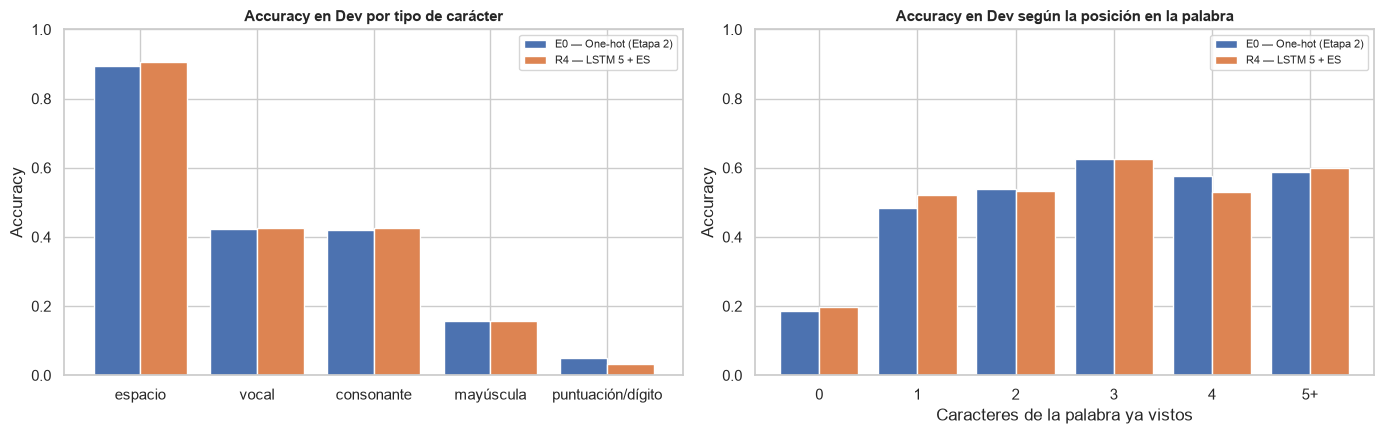

In [10]:
# ==============================================================================
# 5.1 ACCURACY POR TIPO DE CARÁCTER Y POR POSICIÓN EN LA PALABRA
# ==============================================================================
TIPOS_CHAR = ["espacio", "vocal", "consonante", "mayúscula", "puntuación/dígito"]

def tipo_caracter(c):
    if c == " ":
        return "espacio"
    if c.isupper():
        return "mayúscula"
    if c in "aeiou":
        return "vocal"
    if c.isalpha():
        return "consonante"
    return "puntuación/dígito"

def posicion_en_palabra(ctx):
    """Caracteres de la palabra actual ya vistos (0 = el contexto termina en espacio)."""
    p = len(ctx) - 1 - ctx.rfind(" ")
    return str(p) if p < 5 else "5+"

def proba(nombre):
    k = resultados[nombre]["k"]
    return modelos[nombre].predict(Xi_dev[:, -k:], verbose=0)

tipos_dev = np.array([tipo_caracter(c) for c in y_dev])
pos_dev = np.array([posicion_en_palabra(x) for x in X_dev])
POSICIONES = ["0", "1", "2", "3", "4", "5+"]

comparados = list(dict.fromkeys(["E0 — One-hot (Etapa 2)", GANADOR3]))
aciertos = {n: proba(n).argmax(axis=1) == yi_dev for n in comparados}

def acc_por_grupo(grupos, orden):
    df = pd.DataFrame({"Casos en Dev": pd.Series(grupos).value_counts().reindex(orden)})
    for n in comparados:
        df[n] = [aciertos[n][grupos == g].mean() for g in orden]
    if len(comparados) == 2:
        df["Δ (pp)"] = (df[comparados[1]] - df[comparados[0]]) * 100
    return df

df_tipo = acc_por_grupo(tipos_dev, TIPOS_CHAR)
df_pos = acc_por_grupo(pos_dev, POSICIONES)
display(df_tipo.round(4))
display(df_pos.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df_tipo[comparados].plot.bar(ax=axes[0], rot=0, width=0.8)
df_pos[comparados].plot.bar(ax=axes[1], rot=0, width=0.8)
axes[0].set_title("Accuracy en Dev por tipo de carácter", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy en Dev según la posición en la palabra", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Caracteres de la palabra ya vistos")
for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_ylabel("Accuracy")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
# ==============================================================================
# 5.2 DIEZ ERRORES CONCRETOS DEL GANADOR (dos por tipo de carácter)
# ==============================================================================
P_gan = proba(GANADOR3)
pred_gan = P_gan.argmax(axis=1)
errores = np.where(pred_gan != yi_dev)[0]
rng_ej = np.random.default_rng(SEED)

filas_ej = []
for t in TIPOS_CHAR:
    idx_t = errores[tipos_dev[errores] == t]
    for i in rng_ej.choice(idx_t, size=min(2, len(idx_t)), replace=False):
        orden = np.argsort(P_gan[i])[::-1]
        filas_ej.append({
            "Tipo real": t,
            "Contexto (últimos 30)": "..." + X_dev[i][-30:],
            "Real": vis(y_dev[i]),
            "Predicho": vis(idx2char[pred_gan[i]]),
            "Puesto del real": int(np.where(orden == yi_dev[i])[0][0]) + 1,
            "P(real)": round(float(P_gan[i, yi_dev[i]]), 3),
            "Top-5": " | ".join(f"{vis(idx2char[j])} {P_gan[i, j]:.2f}" for j in orden[:5]),
        })

pd.set_option("display.max_colwidth", 60)
display(pd.DataFrame(filas_ej))
print(f"Errores del ganador en Dev: {len(errores)} de {len(yi_dev)} ({len(errores)/len(yi_dev)*100:.2f}%)")

,Tipo real,Contexto (últimos 30),Real,Predicho,Puesto del real,P(real),Top-5
0,espacio,...isting willows writhed against,<SP>,o,4,0.067,o 0.45 | r 0.12 | i 0.07 | <SP> 0.07 | a 0.05
1,espacio,"...bench, so that I could not see",<SP>,n,8,0.019,n 0.42 | m 0.17 | t 0.11 | p 0.08 | c 0.06
2,vocal,...e; and though he made signs th,a,e,2,0.242,e 0.59 | a 0.24 | o 0.07 | i 0.06 | r 0.03
3,vocal,...eassured me; and though he mad,e,<SP>,2,0.241,<SP> 0.41 | e 0.24 | k 0.04 | i 0.04 | n 0.04
4,consonante,...he blasphemous book in my hand,s,<SP>,4,0.041,"<SP> 0.57 | e 0.13 | , 0.10 | s 0.04 | i 0.03"
5,consonante,...had called me to the old town,b,s,6,0.051,s 0.14 | a 0.12 | w 0.11 | t 0.08 | d 0.06
6,mayúscula,...d the first stars of evening.,A,T,3,0.089,T 0.28 | I 0.21 | A 0.09 | W 0.08 | S 0.05
7,mayúscula,...us and wax tablet he carried.,H,T,14,0.009,T 0.34 | I 0.19 | A 0.11 | W 0.06 | B 0.04
8,puntuación/dígito,...sed in a loose antique costume,",",<SP>,6,0.043,<SP> 0.41 | d 0.24 | l 0.09 | n 0.08 | s 0.05
9,puntuación/dígito,... was certainly nervous waiting,",",<SP>,2,0.055,"<SP> 0.87 | , 0.06 | s 0.02 | . 0.01 | ; 0.01"


Errores del ganador en Dev: 1440 de 2880 (50.00%)


**Interpretación.** Los números por tipo y por posición son de un solo modelo (semilla 42), así que diferencias de un par de puntos no son concluyentes.
- **El primer carácter de cada palabra es el problema principal.** En la posición 0 los dos modelos aciertan menos del $20\%$ ($18,59\%$ y $19,77\%$); desde la segunda letra superan el $48\%$. Adivinar qué palabra viene es mucho más difícil que completar una palabra ya empezada.
- **R4 y E0 casi no se diferencian por tipo:** las diferencias van de $-1,67$ a $+1,36$ pp. En puntuación, $-1,67$ pp es un acierto menos sobre 60 casos. Por posición, R4 gana $3,90$ pp en la segunda letra y pierde $4,42$ pp en la quinta.
- **Mayúsculas y puntuación siguen casi sin resolverse:** $15,79\%$ y $3,33\%$, con 38 y 60 casos.
- **Los 10 errores muestran tres patrones:**
  1. **No saber si la palabra terminó.** En `against` y `see` el modelo apuesta a que la palabra sigue (`o`, `n`); en `mad` (de *made*) y `hand` (de *hands*) apuesta al espacio y la palabra seguía.
  2. **Elegir entre continuaciones posibles.** En `signs th` le da $59\%$ a `e` (*the*) y $24\%$ a la real, `a` (*that*). Al empezar la palabra que sigue a `old town`, reparte la probabilidad entre muchas letras y ninguna pasa del $14\%$. Con 5 caracteres, varias respuestas son razonables.
  3. **Mayúsculas y comas.** Después de un punto sabe que viene una mayúscula (`T`, `I` y `A` encabezan su top-5), pero no cuál. En `waiting` le da $87\%$ al espacio y $6\%$ a la coma: sin ver la estructura de la oración, el espacio es mucho más probable.
- **Diagnóstico:** el ganador falla en el $50,00\%$ de Dev. Los patrones 1 y 3 necesitan más contexto que 5 caracteres, que es lo que buscaba la LSTM de 40, pero con este volumen de datos no logró aprovecharlo (secciones 3.2 y 3.3). El patrón 2 no se resuelve con más contexto inmediato.

---
# 6. Qué aprendieron los embeddings
Proyectamos a 2 dimensiones (PCA) los vectores que aprendió para cada carácter el mejor modelo desde cero. Si los caracteres del mismo tipo quedan cerca, el embedding captura algo de su función en el texto.

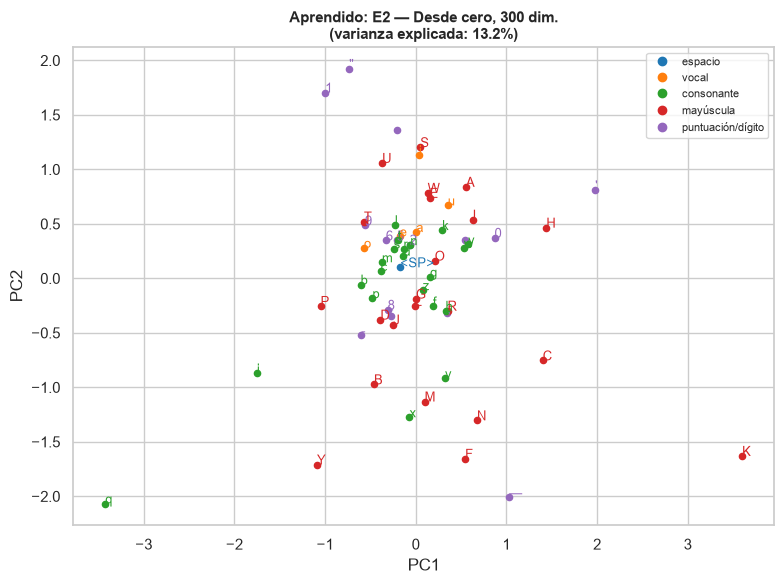

In [12]:
# ==============================================================================
# 6.1 PCA DE LOS EMBEDDINGS
# ==============================================================================
desde_cero = max(["E1 — Desde cero, 16 dim.", "E2 — Desde cero, 300 dim."], key=lambda n: resultados[n]["dev_acc_mean"])
M = modelos[desde_cero].get_layer("embedding").get_weights()[0]
colores = dict(zip(TIPOS_CHAR, sns.color_palette("tab10", len(TIPOS_CHAR))))

fig, ax = plt.subplots(figsize=(8, 6))
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(M)
for c, i in char2idx.items():
    t = tipo_caracter(c)
    ax.scatter(Z[i, 0], Z[i, 1], color=colores[t], s=20)
    ax.annotate(vis(c), (Z[i, 0], Z[i, 1]), fontsize=9, color=colores[t])
ax.set_title(f"Aprendido: {desde_cero}\n(varianza explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)", fontsize=11, fontweight="bold")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
handles = [plt.Line2D([], [], marker="o", ls="", color=colores[t], label=t) for t in TIPOS_CHAR]
ax.legend(handles=handles, fontsize=8, loc="best")
plt.tight_layout()
plt.show()

**Interpretación.**
- **Aprendido desde cero (E2):** los 2 componentes explican solo el $13,2\%$ de la varianza, así que la información está repartida en muchas dimensiones y el gráfico muestra una parte chica. Aun así, las letras ya no se superponen: las minúsculas frecuentes se agrupan en el centro y las mayúsculas y los signos, que aparecen pocas veces en Train, quedan más dispersos.
- **Conclusión:** el embedding aprendido separa las letras entre sí; los caracteres poco frecuentes quedan lejos del grupo central.

---
# 7. Conclusiones de la Etapa 3

1. **Ganador: R4 — LSTM de 5 caracteres con Early Stopping**, con $50,07\% \pm 0,54\%$ en Dev (peor semilla: $49,34\%$): **$+1,36$ pp sobre la Etapa 2** ($48,71\%$) y $+9,24$ pp sobre el baseline. Es R1 cortado a tiempo: en accuracy empatan, pero R4 tiene menos brecha ($10,43$ contra $28,67$ pp), mejor perplejidad ($5,91$ contra $7,64$) y tarda la mitad.
2. **Embeddings de caracteres desde cero:** pasar del one-hot a un embedding aprendido mejora poco ($+0,81$ pp con 300 dimensiones). El tamaño del embedding mueve sobre todo el balance entre acierto y sobreajuste.
3. **Embeddings de palabras, pre-entrenados vs desde cero (sección 8):** GloVe mejora la predicción de la siguiente palabra en unos 3 pp de accuracy top-1 en promedio, aunque con mucho desvío entre semillas. Desde cero, con tan pocas palabras, el modelo casi no aprende más que la frecuencia.
4. **Contexto largo:** la LSTM de 40 caracteres sobreajusta con la configuración heredada (R2, $45,06\%$). Con Early Stopping (R3) sube a $47,76\%$, pero con el mismo esquema la de 5 caracteres la supera por $2,31$ pp.
5. **Dónde sigue fallando:** el primer carácter de cada palabra (menos del $20\%$), las mayúsculas y la puntuación.
6. **Para la Etapa 5:** R4 tiene 247.104 parámetros entrenables y tarda unos 45 s por corrida en CPU.

### 7.1 Registro de experimentos que no funcionaron

| Experimento | Resultado en Dev | Por qué no funcionó |
|---|---|---|
| E1 — Embedding desde cero de 16 dim. | $47,88\% \pm 0,73\%$ | menos capacidad que el one-hot ($-0,83$ pp), aunque con menos sobreajuste |
| R2 — LSTM de 40 caracteres | $45,06\% \pm 1,70\%$ | sobreajusta con la configuración heredada; tarda $583$ s por corrida |
| R3 — LSTM 40 + ES | $47,76\% \pm 0,55\%$ | corrige parte del sobreajuste, pero queda $2,31$ pp debajo de R4 con el mismo esquema |
| Sección 8 — Early Stopping en palabras | ver sección 8 | corta por pérdida antes de que la accuracy deje de subir |

Lo que probamos y sacamos del notebook (ReduceLROnPlateau, embeddings de caracteres pre-entrenados, variantes regularizadas de R3 y el learning rate de $0,005$) está registrado en `docs/EXPERIMENTOS_RETIRADOS.md`.

In [13]:
# ==============================================================================
# 7.2 CHECKLIST DE CUMPLIMIENTO - ETAPA 3
# ==============================================================================
print("=" * 80)
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 3 (UNAB 2026)")
print("=" * 80)
print(f"  [x] 4.3.B Embeddings de caracteres desde cero (16 y 300 dim.) contra el one-hot de la Etapa 2.")
print(f"  [x] 4.3.B Red densa sobre embeddings (misma arquitectura que la Etapa 2).")
print(f"  [x] 4.3.B Modelo de lenguaje simple: LSTM con 5 y {L} caracteres de contexto; las dos con Early Stopping y clipnorm.")
print(f"  [x] 4.3.B Comparación pre-entrenados vs desde cero con embeddings de palabras (GloVe, sección 8; 5 semillas por modelo).")
print(f"  [x] 4.3.B Ejemplos difíciles: {len(filas_ej)} errores concretos, accuracy por tipo y por posición en la palabra.")
print(f"  [x] Mejora sobre la Etapa 2: {GANADOR3} = {r3['dev_acc_mean']*100:.2f}% ({(r3['dev_acc_mean'] - ref2['dev_acc_mean'])*100:+.2f} pp).")
print(f"  [x] Conjunto Test sin evaluar hasta la Etapa 5.")
print("=" * 80)

CHECKLIST DE CUMPLIMIENTO - ETAPA 3 (UNAB 2026)
  [x] 4.3.B Embeddings de caracteres desde cero (16 y 300 dim.) contra el one-hot de la Etapa 2.
  [x] 4.3.B Red densa sobre embeddings (misma arquitectura que la Etapa 2).
  [x] 4.3.B Modelo de lenguaje simple: LSTM con 5 y 40 caracteres de contexto; las dos con Early Stopping y clipnorm.
  [x] 4.3.B Comparación pre-entrenados vs desde cero con embeddings de palabras (GloVe, sección 8; 5 semillas por modelo).
  [x] 4.3.B Ejemplos difíciles: 10 errores concretos, accuracy por tipo y por posición en la palabra.
  [x] Mejora sobre la Etapa 2: R4 — LSTM 5 + ES = 50.07% (+1.36 pp).
  [x] Conjunto Test sin evaluar hasta la Etapa 5.


---
# 8. Consigna 4.3.B: Embeddings de palabras pre-entrenados vs desde cero
La consigna 4.3.B pide **embeddings de palabras** y comparar **pre-entrenados vs entrenados desde cero**. Nuestra tarea principal es a nivel de carácter, y GloVe no tiene vectores de caracteres. Para hacer esa comparación sumamos un experimento aparte: **predecir la siguiente palabra** a partir de las palabras anteriores, con una red densa sobre embeddings de palabras.

**Este experimento no compite con el resto de la etapa.** Es otra tarea (otra salida, otra cantidad de clases), así que su accuracy no se compara con la de caracteres ni entra en la elección del ganador ni en la Etapa 5.

### Decisiones
1. **Tokens:** pasamos el texto limpio a minúsculas y lo cortamos en palabras, signos de puntuación y números. El posesivo se separa (`hill's` → `hill` + `'s`), igual que en el corpus con el que se entrenó GloVe, así más palabras encuentran su vector.
2. **Misma partición por bloques de la Etapa 1:** cortamos en palabras cada bloque por separado, y las ventanas se arman solo dentro de cada bloque. Una palabra que cruza el borde entre dos bloques queda partida en dos, un efecto mínimo con 50 bloques. Así no hay fuga entre Train y Dev, por la misma razón que en la Etapa 1.
3. **Contexto de $N = 3$ palabras:** el corpus tiene unos 4.000 tokens, así que contextos más largos casi no se repiten entre Train y Dev.
4. **Vocabulario de salida:** las palabras de Train más un token `<UNK>` para las que no aparecen en Train. Una palabra de Dev que no está en Train **cuenta siempre como error**, aunque el modelo prediga `<UNK>`: no tiene sentido premiar "acertar que no se sabe".
5. **Pre-entrenados:** GloVe 6B de 100 dimensiones (Wikipedia 2014 + Gigaword 5, 400.000 palabras en minúsculas; Pennington, Socher y Manning, 2014). Los tokens sin vector arrancan al azar, con la misma escala que el resto.
6. **Tres modelos con la misma red densa de las secciones anteriores** (Dense 128 → 64 → 32 con ReLU y Dropout), 5 semillas cada uno:

| Modelo | Embedding de cada palabra |
|---|---|
| **P0 — Desde cero** | 100 dim., aprendido junto con la red |
| **P1 — GloVe congelado** | vectores de GloVe fijos |
| **P2 — GloVe ajustable** | vectores de GloVe como punto de partida, ajustados durante el entrenamiento |

7. **Early Stopping en los tres** (paciencia 5 sobre `val_loss`, con los mejores pesos): con unas 2.800 ventanas de entrenamiento y 1.000 clases, sin cortar el entrenamiento los tres sobreajustan enseguida. Aplicarlo a todos mantiene la comparación pareja.
8. **Métricas:** accuracy top-1 en Dev, como en el resto del TP, y accuracy **top-5** (el real está entre las 5 palabras más probables), porque con tantas clases la top-1 es muy baja. Como referencia, predecir siempre la palabra más frecuente de Train.

In [14]:
# ==============================================================================
# 8.1 TOKENIZACIÓN EN PALABRAS Y VENTANAS POR BLOQUES
# ==============================================================================
import re
import zipfile

N_PAL = 3            # Palabras de contexto
DIM_PAL = 100        # Dimensión de los embeddings de palabras
UNK = "<UNK>"

# Palabras, sufijos con apóstrofo ('s), números o un signo suelto
patron = re.compile(r"[a-z]+|'[a-z]+|[0-9]+|[^\sa-z0-9]")

# Cada bloque de la Etapa 1 se corta en palabras por separado: así cada palabra queda en un solo conjunto
tokens_por_bloque = {b: patron.findall(text[ini:fin].lower()) for b, (ini, fin) in enumerate(limites)}
n_tokens = sum(len(t) for t in tokens_por_bloque.values())

def ventanas_palabras(ids):
    X, y = [], []
    for b in ids:
        toks = tokens_por_bloque.get(b, [])
        for i in range(N_PAL, len(toks)):
            X.append(toks[i - N_PAL:i])
            y.append(toks[i])
    return X, y

Xp_train, yp_train = ventanas_palabras(bloques_split["train"])
Xp_dev,   yp_dev   = ventanas_palabras(bloques_split["dev"])

# Vocabulario: palabras de Train (contexto y objetivo) más <UNK>
vocab_pal = [UNK] + sorted({t for b in bloques_split["train"] for t in tokens_por_bloque.get(b, [])})
pal2idx = {p: i for i, p in enumerate(vocab_pal)}
VP = len(vocab_pal)
a_idx = lambda toks: [pal2idx.get(t, 0) for t in toks]

Xpi_train = np.array([a_idx(x) for x in Xp_train], dtype=np.int32)
Xpi_dev   = np.array([a_idx(x) for x in Xp_dev], dtype=np.int32)
ypi_train = np.array(a_idx(yp_train), dtype=np.int32)
ypi_dev   = np.array(a_idx(yp_dev), dtype=np.int32)

frec_pal = Counter(yp_train)
mas_frec = frec_pal.most_common(1)[0][0]
oov_dev = float(np.mean(ypi_dev == 0))
acc_mayoritaria_pal = float(np.mean(np.array(yp_dev) == mas_frec))

print(f"Tokens en el texto: {n_tokens:,} | vocabulario de Train: {VP - 1:,} palabras + <UNK>")
print(f"Ventanas de {N_PAL} palabras -> Train: {len(Xp_train):,} | Dev: {len(Xp_dev):,}")
print(f"Palabras de Dev que no aparecen en Train: {oov_dev*100:.1f}% (techo de accuracy: {(1-oov_dev)*100:.1f}%)")
print(f"Referencia: predecir siempre '{mas_frec}' -> {acc_mayoritaria_pal*100:.2f}% en Dev")
print(f"Ejemplo: {Xp_train[0]} -> {yp_train[0]!r}")

Tokens en el texto: 4,087 | vocabulario de Train: 999 palabras + <UNK>
Ventanas de 3 palabras -> Train: 2,777 | Dev: 616
Palabras de Dev que no aparecen en Train: 25.2% (techo de accuracy: 74.8%)
Referencia: predecir siempre 'the' -> 7.63% en Dev
Ejemplo: ['e', 'tongue', 'of'] -> 'the'


In [15]:
# ==============================================================================
# 8.2 CARGA DE GLOVE 6B (100 dim.) Y COBERTURA DEL VOCABULARIO
# ==============================================================================
URL_GLOVE = "https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip"  # mirror oficial de Stanford NLP
RUTA_GLOVE = BASE_DIR / "data" / "external" / "glove.6B.zip"
if not RUTA_GLOVE.exists():
    # Descarga única de unos 860 MB
    RUTA_GLOVE.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL_GLOVE, RUTA_GLOVE)

# Leemos el archivo dentro del zip y guardamos solo los vectores de nuestro vocabulario
glove = {}
with zipfile.ZipFile(RUTA_GLOVE) as z, z.open(f"glove.6B.{DIM_PAL}d.txt") as f:
    for linea in f:
        partes = linea.decode("utf-8").rstrip().split(" ")
        if partes[0] in pal2idx:
            glove[partes[0]] = np.array(partes[1:], dtype=np.float32)

rng_pal = np.random.default_rng(SEED)
escala_pal = np.std(np.stack(list(glove.values())))
E_glove = np.zeros((VP, DIM_PAL), dtype=np.float32)
sin_vector_pal = []
for p, i in pal2idx.items():
    if p in glove:
        E_glove[i] = glove[p]
    else:
        E_glove[i] = rng_pal.normal(0, escala_pal, DIM_PAL)
        sin_vector_pal.append(p)

cubiertos = sum(frec_pal[p] for p in glove) / sum(frec_pal.values())
print(f"Palabras del vocabulario con vector de GloVe: {len(glove):,} de {VP - 1:,}")
print(f"Objetivos de Train cubiertos por GloVe: {cubiertos*100:.1f}%")
print(f"Sin vector (primeras 15): {[p for p in sin_vector_pal if p != UNK][:15]}")

Palabras del vocabulario con vector de GloVe: 959 de 999
Objetivos de Train cubiertos por GloVe: 98.9%
Sin vector (primeras 15): ["'clock", 'amorphously', 'chimneypots', 'creakin', 'daemonolatreia', 'eckoning', 'feastings', 'footworn', 'fungous', 'glanvil', 'hastes', 'hearthside', 'hispered', 'lichened', 'loathsomely']


  P0 — Desde cero        Dev top-1: 8.08% ± 1.02% | top-5: 23.54% | 11 épocas | 2.7 s por corrida


  P1 — GloVe congelado   Dev top-1: 10.81% ± 2.84% | top-5: 25.49% | 11 épocas | 2.6 s por corrida


  P2 — GloVe ajustable   Dev top-1: 11.72% ± 2.76% | top-5: 25.58% | 11 épocas | 2.7 s por corrida

Referencia (siempre 'the'): 7.63% | techo por palabras nuevas: 74.8%


,Parámetros entrenables,Dev top-1 (μ ± σ),Dev top-5 (μ ± σ),Train top-1,Brecha,Perplejidad,Épocas
Modelo,,,,,,,
P0 — Desde cero,"181,864",8.08% ± 1.02%,23.54% ± 0.00%,7.16%,-0.93 pp,443.4,11
P1 — GloVe congelado,"81,864",10.81% ± 2.84%,25.49% ± 1.57%,10.04%,-0.77 pp,516.2,11
P2 — GloVe ajustable,"181,864",11.72% ± 2.76%,25.58% ± 1.45%,10.79%,-0.93 pp,503.8,11


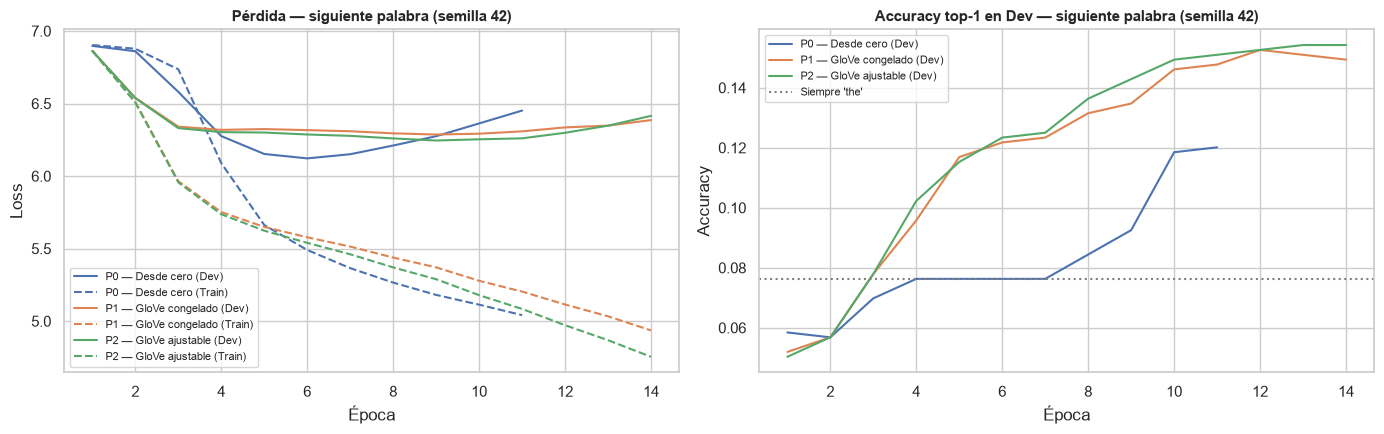

In [16]:
# ==============================================================================
# 8.3 RED DENSA SOBRE EMBEDDINGS DE PALABRAS (5 semillas)
# ==============================================================================
def construir_red_palabras(emb_init=None, emb_trainable=True, dropout=DROPOUT):
    """Embedding de palabras -> Flatten -> MLP 128-64-32 -> softmax sobre el vocabulario."""
    entrada = layers.Input(shape=(N_PAL,), dtype="int32")
    init = keras.initializers.Constant(emb_init) if emb_init is not None else "uniform"
    x = layers.Embedding(VP, DIM_PAL, embeddings_initializer=init, trainable=emb_trainable, name="embedding")(entrada)
    x = layers.Flatten()(x)
    for u in [128, 64, 32]:
        x = layers.Dense(u, activation="relu")(x)
        if dropout > 0:
            x = layers.Dropout(dropout)(x)
    salida = layers.Dense(VP, activation="softmax")(x)
    return keras.Model(entrada, salida)

def acc_topk(P, y, k):
    """Accuracy top-k; una palabra fuera del vocabulario de Train (<UNK>) cuenta siempre como error."""
    # 1) En cada fila, las k columnas (palabras) de mayor probabilidad
    topk = np.argsort(P, axis=1)[:, ::-1][:, :k]
    # 2) ¿La palabra real está entre esas k? (y[:, None] la pone como columna para comparar fila por fila)
    en_topk = (topk == y[:, None]).any(axis=1)
    # 3) Una palabra que no está en Train (<UNK>, índice 0) cuenta siempre como error
    return float(np.mean(en_topk & (y != 0)))

def evaluar_palabras(constructor):
    corridas = []
    for s in SEEDS:
        keras.utils.set_random_seed(s)
        modelo = constructor()
        modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=LR),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        es = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
        t0 = time.perf_counter()
        h = modelo.fit(Xpi_train, ypi_train, validation_data=(Xpi_dev, ypi_dev), epochs=EPOCAS,
                       batch_size=BATCH, callbacks=[es], verbose=0)
        t_run = time.perf_counter() - t0
        if s == SEED:
            h42, m42 = h.history, modelo
        P_tr, P_dv = modelo.predict(Xpi_train, verbose=0), modelo.predict(Xpi_dev, verbose=0)
        loss_dv = float(modelo.evaluate(Xpi_dev, ypi_dev, verbose=0)[0])
        corridas.append({"seed": s, "tiempo": t_run, "epocas": len(h.history["loss"]),
                         "train_acc": acc_topk(P_tr, ypi_train, 1), "dev_acc": acc_topk(P_dv, ypi_dev, 1),
                         "dev_top5": acc_topk(P_dv, ypi_dev, 5), "dev_loss": loss_dv, "dev_perp": float(np.exp(loss_dv))})
        corridas[-1]["brecha"] = corridas[-1]["train_acc"] - corridas[-1]["dev_acc"]
    df_c = pd.DataFrame(corridas)
    resumen = {"params": int(sum(np.prod(w.shape) for w in m42.trainable_weights)), "corridas": corridas}
    for col in df_c.columns.drop("seed"):
        resumen[f"{col}_mean"] = float(df_c[col].mean())
        resumen[f"{col}_std"] = float(df_c[col].std())
    return resumen, h42, m42

MODELOS_PAL = {
    "P0 — Desde cero":       lambda: construir_red_palabras(),
    "P1 — GloVe congelado":  lambda: construir_red_palabras(emb_init=E_glove, emb_trainable=False),
    "P2 — GloVe ajustable":  lambda: construir_red_palabras(emb_init=E_glove, emb_trainable=True),
}
resultados_pal, historiales_pal, modelos_pal = {}, {}, {}
for nombre, constructor in MODELOS_PAL.items():
    resultados_pal[nombre], historiales_pal[nombre], modelos_pal[nombre] = evaluar_palabras(constructor)
    r = resultados_pal[nombre]
    print(f"  {nombre:<22} Dev top-1: {r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}% | "
          f"top-5: {r['dev_top5_mean']*100:.2f}% | {r['epocas_mean']:.0f} épocas | {r['tiempo_mean']:.1f} s por corrida")

df_pal = pd.DataFrame([{
    "Modelo": n, "Parámetros entrenables": f"{r['params']:,}",
    "Dev top-1 (μ ± σ)": f"{r['dev_acc_mean']*100:.2f}% ± {r['dev_acc_std']*100:.2f}%",
    "Dev top-5 (μ ± σ)": f"{r['dev_top5_mean']*100:.2f}% ± {r['dev_top5_std']*100:.2f}%",
    "Train top-1": f"{r['train_acc_mean']*100:.2f}%", "Brecha": f"{r['brecha_mean']*100:.2f} pp",
    "Perplejidad": f"{r['dev_perp_mean']:.1f}", "Épocas": f"{r['epocas_mean']:.0f}",
} for n, r in resultados_pal.items()]).set_index("Modelo")
print(f"\nReferencia (siempre '{mas_frec}'): {acc_mayoritaria_pal*100:.2f}% | techo por palabras nuevas: {(1-oov_dev)*100:.1f}%")
display(df_pal)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for n, h in historiales_pal.items():
    ep = range(1, len(h["loss"]) + 1)
    l = axes[0].plot(ep, h["val_loss"], label=f"{n} (Dev)")[0]
    axes[0].plot(ep, h["loss"], color=l.get_color(), linestyle="--", label=f"{n} (Train)")
    axes[1].plot(ep, h["val_accuracy"], color=l.get_color(), label=f"{n} (Dev)")
axes[1].axhline(acc_mayoritaria_pal, color="gray", linestyle=":", label=f"Siempre '{mas_frec}'")
axes[0].set_title("Pérdida — siguiente palabra (semilla 42)", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy top-1 en Dev — siguiente palabra (semilla 42)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [17]:
# ==============================================================================
# 8.4 VECINOS MÁS CERCANOS: QUÉ SABE CADA EMBEDDING
# ==============================================================================
def vecinos(E, palabra, n=5):
    """Las n palabras del vocabulario más parecidas (similitud coseno)."""
    En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
    sim = En @ En[pal2idx[palabra]]
    orden = [j for j in np.argsort(sim)[::-1] if j not in (0, pal2idx[palabra])]
    return ", ".join(vocab_pal[j] for j in orden[:n])

E_cero = modelos_pal["P0 — Desde cero"].get_layer("embedding").get_weights()[0]
palabras_ej = [p for p in ["night", "old", "town", "sea", "dead", "candle"] if p in pal2idx]
display(pd.DataFrame({
    "GloVe (pre-entrenado)": {p: vecinos(E_glove, p) for p in palabras_ej},
    "Desde cero (P0, semilla 42)": {p: vecinos(E_cero, p) for p in palabras_ej},
}))

with open(PROC / "resultados_palabras.json", "w", encoding="utf-8") as f:
    json.dump({"config": {"N": N_PAL, "dim": DIM_PAL, "lr": LR, "dropout": DROPOUT, "batch": BATCH,
                          "epocas_max": EPOCAS, "es_patience": 5, "fuente_glove": URL_GLOVE},
               "datos": {"tokens": n_tokens, "vocabulario": VP - 1, "n_train": len(Xp_train), "n_dev": len(Xp_dev),
                         "oov_dev": oov_dev, "palabra_mas_frecuente": mas_frec, "acc_mayoritaria_dev": acc_mayoritaria_pal,
                         "con_vector_glove": len(glove)},
               "resultados": resultados_pal}, f, indent=2, ensure_ascii=False, default=float)
print("Resultados guardados en data/processed/resultados_palabras.json")

,GloVe (pre-entrenado),"Desde cero (P0, semilla 42)"
night,"before, time, last, when, on","back, at, its, be, squirming"
old,"man, father, one, woman, now","had, stuck, serpentine, the, outspread"
town,"near, where, outside, around, part","walls, founded, pillar, bare, table"
sea,"waters, water, fishing, shore, river","taverns, to, everything, not, remained"


Resultados guardados en data/processed/resultados_palabras.json


**Interpretación.**
- **Las palabras nuevas ponen un techo bajo.** El $25,2\%$ de las palabras de Dev no aparece en Train, así que ningún modelo puede pasar del $74,8\%$. La referencia de predecir siempre *the* da $7,63\%$.
- **P0, entrenado desde cero, casi no aprende:** $8,08\% \pm 1,02\%$. En 4 de las 5 semillas da exactamente $7,63\%$, lo mismo que predecir siempre *the*: Early Stopping recupera los pesos de una época en la que el modelo solo aprendió la palabra más frecuente. Con 2.777 ventanas y 999 palabras, la mayoría aparece pocas veces en Train. Sus vecinos no tienen relación de significado (*sea* → *taverns*, *to*, *everything*).
- **GloVe ayuda, pero con mucha variación.** P1 llega a $10,81\% \pm 2,84\%$ y P2 a $11,72\% \pm 2,76\%$ ($+2,73$ y $+3,64$ pp sobre P0), y el top-5 sube de $23,54\%$ a $25,49\%$ y $25,58\%$. Los desvíos son altos porque en algunas semillas también quedan cerca de *the*. GloVe tiene vector para 959 de las 999 palabras, y sus vecinos tienen sentido (*sea* → *waters*, *water*, *fishing*, *shore*, *river*).
- **Congelar o ajustar da lo mismo:** P2 supera a P1 por $0,91$ pp, dentro del desvío, y P1 entrena menos de la mitad de parámetros (81.864 contra 181.864).
- **Por qué con palabras sí:** una palabra tiene un significado que GloVe trae aprendido de un corpus de 6.000 millones de tokens; con pocos datos propios, eso es justo lo que falta.
- **Limitación: Early Stopping corta antes de tiempo.** Los tres modelos paran a las 11 épocas en promedio y recuperan la época de menor `val_loss`. En las curvas de la semilla 42, la pérdida en Dev toca su mínimo cerca de la época 6 (P0) y 9 (P1 y P2), pero la accuracy sigue subiendo: P1 y P2 llegan a cerca del $15\%$ entre las épocas 12 y 14, y P0 pasa de $7,6\%$ a $12\%$ entre las épocas 7 y 11. Por eso la accuracy en Train queda incluso por debajo de la de Dev, y las cifras de la tabla subestiman a los tres modelos.